# Prefill: TTFT vs prompt length

## Performance of each phase of an LLM, starting with prefill

- **Prefill (this benchmark):** n prompts multiplied with weight matrices; builds the KV cache. Weights ~ n·d², attention ~ n²·d. Compute-bound.
- **Decode (TODO):** one token per step, re-reading weights and the whole KV cache. Memory-bandwidth-bound.
- **Hardware considerations:** which GPU, which precision, memory requirements, how much context to allow.

### Investigating prefill: where the KV cache is built and attention grows as n²

1. **Signal:** headlines about one ticker, and one question about it.
2. **Noise:** add 50 to 1,000 unrelated headlines to lengthen the prompt.
3. **Measure:** time to first token; 3 repeats, cache off.

First, naive version: all headlines and any question gave poor answers and no control over length.

## TTFT scales with prompt length non-linearly

Qwen3-4B (4-bit) on vllm-mlx · Apple M1, 8 GB · median of 3 repeats per point · prefix cache off, unique prompt per request. Data: [`results/ttft-prefill-baseline.csv`](results/ttft-prefill-baseline.csv), config: [`configs/ttft-prefill-baseline.yaml`](configs/ttft-prefill-baseline.yaml).

t ≈ 6.19 ms·n + 0.21 µs·n²
151 → 94 tokens/s, crossover n* = b/c ≈ 30,018 tokens


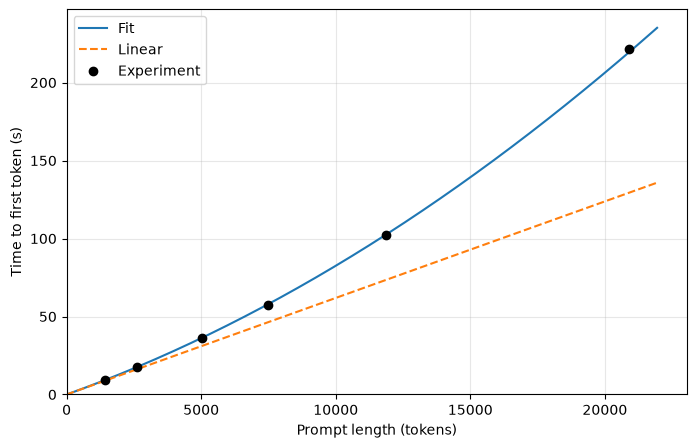

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("results/ttft-prefill-baseline.csv")
m = df[df.ok].groupby("noise_headlines")[["prompt_tokens", "ttft_s"]].median()
n, t = m.prompt_tokens.to_numpy(), m.ttft_s.to_numpy()
b, c = np.linalg.lstsq(np.c_[n, n**2] / t[:, None], np.ones_like(t), rcond=None)[0]

print(f"t ≈ {b * 1e3:.2f} ms·n + {c * 1e6:.2f} µs·n²")
print(f"{n[0] / t[0]:.0f} → {n[-1] / t[-1]:.0f} tokens/s, crossover n* = b/c ≈ {b / c:,.0f} tokens")

x = np.linspace(0, 1.05 * n.max(), 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, b * x + c * x**2, label="Fit")
ax.plot(x, b * x, "--", label="Linear")
ax.plot(n, t, "ko", label="Experiment")
ax.set(xlabel="Prompt length (tokens)", ylabel="Time to first token (s)", xlim=(0, None), ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend();

## Prefill (compute bound) vs decode (memory bound)

| | Prefill: reading the prompt | Decode: writing the answer |
|---|---|---|
| Input | n prompt tokens, all at once | 1 new token |
| Attention (each of 36 layers) | every token vs every earlier one: n² | new token vs all n cached: n |
| Weight multiplies | same cost per token: n | all weights re-read for one token |
| KV cache (keys and values of every token so far) | writes one entry per prompt token | read in full each step, one entry added |
| Output | first token · time to first token | next token · repeat until done |

Simplified decoder-only transformer, reference Vaswani et al., “Attention Is All You Need”, NeurIPS 2017 ([arXiv:1706.03762](https://arxiv.org/abs/1706.03762)). Layer count is Qwen3-4B’s.

## Prefill and decode stress different hardware

| | Prefill: reading the prompt | Decode: writing the answer |
|---|---|---|
| Tokens per step | all n prompt tokens at once | one |
| Weight multiplies | matrix × matrix: each weight loaded once, used by n tokens | matrix × vector: every weight loaded again for each token |
| Attention | every token against every earlier one: grows as n² | the new token against n cached keys: grows as n |
| KV cache | written, one entry per prompt token: grows as n | read in full every step, one entry appended |
| Bottleneck | compute (FLOP/s) | memory bandwidth (bytes/s) |
| What users see | time to first token | milliseconds per output token |
| GPU feature that helps | tensor-core throughput, FP8/FP4 | HBM bandwidth (H200 about 4.8 TB/s) |

Measured so far: prefill. Decode sweep next, same harness.